# 03 — Hyperparameter Tuning and Final Training

## Robustness-Enhanced Vision-Language-Action Learning

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Framework:** Hugging Face LeRobot `v0.6.1`  
**Benchmark:** LIBERO-Spatial  
**Trainable initialization:** `lerobot/smolvla_base`

---

### Notebook objective

Notebook 00 established the dataset and frozen train/validation split.  
Notebook 01 established closed-loop SmolVLA ↔ LIBERO compatibility.  
Notebook 02 established that M1 and M2-E can perform real back-propagation, save checkpoints, and reload correctly, and it froze the M2-L language specification.

Notebook 03 now performs the **actual model-selection and final-training stage**:

1. verify Notebook 02 and all frozen artifacts,
2. construct a common LIBERO-compatible SmolVLA fine-tuning configuration,
3. validate one shared custom training loop that supports both language and visual robustness augmentation,
4. tune a compact learning-rate / weight-decay search using **only the frozen validation split**,
5. freeze the best optimizer setting,
6. train the final M1 / M2-L / M2-E / M2-LE models,
7. run the main M1 vs M2-LE comparison with three seeds,
8. preserve single-seed M2-L / M2-E runs as ablations,
9. save complete experiment manifests and a final Notebook 03 summary.

### Important scientific boundary

The primary research outcome is **closed-loop task success under ID and OOD perturbations**, which is evaluated in Notebook 04.

The validation loss used here is only a **model-selection signal**. It must not be interpreted as the final robustness result.

## 1. Final experiment structure

| Model | Training condition | Final seeds | Role |
|---|---|---:|---|
| M1 | Original language + original images | 42, 123, 2026 | Standard fine-tuning baseline |
| M2-L | L0/L1/L2 language variation | 42 | Language ablation |
| M2-E | Photometric image augmentation | 42 | Environment ablation |
| M2-LE | L0/L1/L2 + photometric augmentation | 42, 123, 2026 | Main proposed robustness model |

This design gives a **three-seed primary comparison** between M1 and M2-LE while keeping the two intermediate ablations computationally tractable.

## 2. Environment, paths and fixed training budget

In [2]:
import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
from copy import deepcopy
from datetime import datetime
import gc
import hashlib
import json
import math
import random
import shutil
import subprocess
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch.utils.data import DataLoader, Dataset, Subset

# ------------------------------------------------------------------
# Fixed experimental constants
# ------------------------------------------------------------------

DATASET_REPO_ID = "lerobot/libero"
BASE_MODEL_REPO_ID = "lerobot/smolvla_base"
LIBERO_SUITE = "libero_spatial"
VIDEO_BACKEND = "pyav"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Compact, compute-aware tuning stage.
TUNING_SEED = 42
TUNING_STEPS = 200
TUNING_BATCH_SIZE = 4

# Final training budget.
FINAL_STEPS = 1500
FINAL_BATCH_SIZE = 4

# Validation uses a frozen, balanced frame subset.
VAL_FRAMES_PER_TASK = 20
VAL_BATCH_SIZE = 4

# Optimization controls shared by every trainable variant.
GRAD_CLIP_NORM = 10.0
WARMUP_FRACTION = 0.10
MIN_LR_RATIO = 0.025
LOG_EVERY = 25

PRIMARY_SEEDS = [42, 123, 2026]

# ------------------------------------------------------------------
# Repository paths
# ------------------------------------------------------------------

def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate
    if current.name == "notebooks":
        return current.parent
    return current

REPO_ROOT = find_repo_root(Path.cwd())

CONFIG_DIR = REPO_ROOT / "configs"
SPLIT_DIR = CONFIG_DIR / "splits"
EXPERIMENT_CONFIG_DIR = CONFIG_DIR / "experiments"

RESULTS_DIR = REPO_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics" / "tuning_final_training"
FIGURES_DIR = RESULTS_DIR / "figures" / "tuning_final_training"

TUNING_OUTPUT_DIR = REPO_ROOT / "experiments" / "tuning"
FINAL_OUTPUT_DIR = REPO_ROOT / "experiments" / "training" / "final"

for directory in [
    EXPERIMENT_CONFIG_DIR,
    METRICS_DIR,
    FIGURES_DIR,
    TUNING_OUTPUT_DIR,
    FINAL_OUTPUT_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None

PROJECT_GIT_SHA = git_sha(REPO_ROOT)

environment_summary = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "device": DEVICE,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "project_git_sha": PROJECT_GIT_SHA,
    "tuning_steps_per_config": TUNING_STEPS,
    "final_steps_per_run": FINAL_STEPS,
}

display(pd.DataFrame([environment_summary]).T.rename(columns={0: "Value"}))

assert torch.cuda.is_available(), (
    "Notebook 03 final training is configured for CUDA. "
    "Use the validated vla-libero GPU environment."
)

,Value
python,3.12.14
torch,2.11.0+cu128
cuda_available,True
device,cuda
gpu,NVIDIA GeForce RTX 5090
project_git_sha,82ad3cdb2deb9f40414a28c65fb327785b343183
tuning_steps_per_config,200
final_steps_per_run,1500


### Compute budget rationale

The search is intentionally compact:

- 3 learning rates,
- 2 weight-decay values,
- 200 steps per candidate,
- one tuning seed.

This gives **6 controlled tuning runs**, rather than a large brute-force sweep.

After selecting the optimizer setting, the same setting is frozen for all final variants. This prevents each robustness method from receiving a different optimization advantage.

## 3. Verify Notebook 02 and load frozen artifacts

In [3]:
NOTEBOOK02_SUMMARY_PATH = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "robustness_training"
    / "notebook02_summary.json"
)

assert NOTEBOOK02_SUMMARY_PATH.exists(), (
    f"Missing Notebook 02 summary: {NOTEBOOK02_SUMMARY_PATH}"
)

with open(NOTEBOOK02_SUMMARY_PATH, "r") as f:
    notebook02_summary = json.load(f)

assert notebook02_summary["status"] == "PASS", (
    "Notebook 03 requires Notebook 02 STATUS = PASS."
)

DATASET_REVISION = notebook02_summary["dataset_revision"]
BASE_MODEL_REVISION = notebook02_summary["base_model_revision"]

frozen_split_path = REPO_ROOT / notebook02_summary["split_file"]
language_table_path = REPO_ROOT / notebook02_summary["language_table"]

assert frozen_split_path.exists()
assert language_table_path.exists()

frozen_split_df = pd.read_csv(frozen_split_path)
language_df = pd.read_csv(language_table_path)

frozen_split_df["split"] = (
    frozen_split_df["split"]
    .astype(str)
    .str.lower()
    .str.strip()
    .replace({"val": "validation", "valid": "validation"})
)

train_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df["split"] == "train",
        "episode_index",
    ].astype(int).tolist()
)

validation_ids = sorted(
    frozen_split_df.loc[
        frozen_split_df["split"] == "validation",
        "episode_index",
    ].astype(int).tolist()
)

assert len(train_ids) == 346
assert len(validation_ids) == 86
assert set(train_ids).isdisjoint(validation_ids)

assert len(language_df) == 40
assert language_df["task_id"].nunique() == 10
assert set(language_df["level"]) == {"L0", "L1", "L2", "L3"}
assert (language_df["semantic_review"] == "PASS").all()

prior_summary = {
    "Notebook 02 status": notebook02_summary["status"],
    "dataset_revision": DATASET_REVISION,
    "base_model_revision": BASE_MODEL_REVISION,
    "train_episodes": len(train_ids),
    "validation_episodes": len(validation_ids),
    "language_rows": len(language_df),
    "language_training_levels": notebook02_summary["language_training_levels"],
    "language_held_out_level": notebook02_summary["language_held_out_level"],
}

display(pd.DataFrame([prior_summary]).T.rename(columns={0: "Value"}))

print("NOTEBOOK 02 + FROZEN ARTIFACTS: PASS")

,Value
Notebook 02 status,PASS
dataset_revision,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
base_model_revision,c83c3163b8ca9b7e67c509fffd9121e66cb96205
train_episodes,346
validation_episodes,86
language_rows,40
language_training_levels,"[L0, L1, L2]"
language_held_out_level,L3


NOTEBOOK 02 + FROZEN ARTIFACTS: PASS


## 4. Reconstruct the LIBERO-compatible SmolVLA configuration

In [4]:
from huggingface_hub import snapshot_download

from lerobot.configs import FeatureType
from lerobot.datasets import LeRobotDataset, LeRobotDatasetMetadata
from lerobot.datasets.factory import resolve_delta_timestamps
from lerobot.policies import make_pre_post_processors
from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.transforms import (
    ImageTransformConfig,
    ImageTransforms,
    ImageTransformsConfig,
)
from lerobot.utils.collate import lerobot_collate_fn
from lerobot.utils.feature_utils import dataset_to_policy_features

BASE_MODEL_SNAPSHOT = Path(
    snapshot_download(
        repo_id=BASE_MODEL_REPO_ID,
        revision=BASE_MODEL_REVISION,
    )
)

dataset_meta = LeRobotDatasetMetadata(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
)

policy_features = dataset_to_policy_features(
    dataset_meta.features
)

output_features = {
    key: feature
    for key, feature in policy_features.items()
    if feature.type is FeatureType.ACTION
}

input_features = {
    key: feature
    for key, feature in policy_features.items()
    if key not in output_features
}

BASE_POLICY_CONFIG = SmolVLAConfig.from_pretrained(
    str(BASE_MODEL_SNAPSHOT)
)

# Replace the original pretraining feature schema with LIBERO's schema.
BASE_POLICY_CONFIG.input_features = input_features
BASE_POLICY_CONFIG.output_features = output_features
BASE_POLICY_CONFIG.device = DEVICE
BASE_POLICY_CONFIG.push_to_hub = False

DELTA_TIMESTAMPS = resolve_delta_timestamps(
    BASE_POLICY_CONFIG,
    dataset_meta,
)

config_summary = {
    "policy_type": BASE_POLICY_CONFIG.type,
    "input_features": list(BASE_POLICY_CONFIG.input_features),
    "output_features": list(BASE_POLICY_CONFIG.output_features),
    "chunk_size": BASE_POLICY_CONFIG.chunk_size,
    "n_action_steps": BASE_POLICY_CONFIG.n_action_steps,
    "freeze_vision_encoder": BASE_POLICY_CONFIG.freeze_vision_encoder,
    "train_expert_only": BASE_POLICY_CONFIG.train_expert_only,
    "train_state_proj": BASE_POLICY_CONFIG.train_state_proj,
    "base_optimizer_lr": BASE_POLICY_CONFIG.optimizer_lr,
    "base_optimizer_weight_decay": BASE_POLICY_CONFIG.optimizer_weight_decay,
    "grad_clip_norm": BASE_POLICY_CONFIG.optimizer_grad_clip_norm,
}

display(pd.DataFrame([config_summary]).T.rename(columns={0: "Value"}))

print("LIBERO-COMPATIBLE SMOLVLA CONFIG: PASS")

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1436.41it/s]


,Value
policy_type,smolvla
input_features,"[observation.images.image, observation.images...."
output_features,[action]
chunk_size,50
n_action_steps,50
freeze_vision_encoder,True
train_expert_only,True
train_state_proj,True
base_optimizer_lr,0.0001
base_optimizer_weight_decay,0.0


LIBERO-COMPATIBLE SMOLVLA CONFIG: PASS


## 5. Build the frozen train and validation datasets

In [5]:
base_train_dataset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=train_ids,
    delta_timestamps=DELTA_TIMESTAMPS,
    video_backend=VIDEO_BACKEND,
    return_uint8=True,
)

base_validation_dataset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=validation_ids,
    delta_timestamps=DELTA_TIMESTAMPS,
    video_backend=VIDEO_BACKEND,
    return_uint8=True,
)

assert base_train_dataset.num_episodes == 346
assert base_validation_dataset.num_episodes == 86

sample = base_train_dataset[0]

required_runtime_keys = {
    "task",
    "task_index",
    "episode_index",
    "action",
}

missing_runtime_keys = required_runtime_keys - set(sample)
assert not missing_runtime_keys, (
    f"Training sample missing required keys: {sorted(missing_runtime_keys)}"
)

dataset_runtime_summary = {
    "train_frames": base_train_dataset.num_frames,
    "train_episodes": base_train_dataset.num_episodes,
    "validation_frames": base_validation_dataset.num_frames,
    "validation_episodes": base_validation_dataset.num_episodes,
    "camera_keys": list(dataset_meta.camera_keys),
    "task_key_available": "task" in sample,
}

display(pd.DataFrame([dataset_runtime_summary]).T.rename(columns={0: "Value"}))

print("FROZEN DATASET RUNTIME CHECK: PASS")

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1360.02it/s]


,Value
train_frames,42156
train_episodes,346
validation_frames,10814
validation_episodes,86
camera_keys,"[observation.images.image, observation.images...."
task_key_available,True


FROZEN DATASET RUNTIME CHECK: PASS


## 6. Freeze a balanced validation subset

Hyperparameter selection should not depend on a randomly changing sample.

Notebook 03 therefore chooses **20 validation frames per task** using deterministic, evenly spaced positions inside the frozen validation split:

`10 tasks × 20 frames = 200 validation samples`

The exact frame positions are saved to `configs/experiments/validation_frame_subset_v1.csv`.

In [6]:
validation_task_array = np.asarray(
    base_validation_dataset.hf_dataset["task_index"],
    dtype=int,
)

validation_positions = []

for task_id in sorted(np.unique(validation_task_array)):
    task_positions = np.flatnonzero(
        validation_task_array == task_id
    )

    assert len(task_positions) >= VAL_FRAMES_PER_TASK

    chosen_offsets = np.linspace(
        0,
        len(task_positions) - 1,
        VAL_FRAMES_PER_TASK,
        dtype=int,
    )

    chosen_positions = task_positions[chosen_offsets]

    for position in chosen_positions:
        raw_row = base_validation_dataset.hf_dataset[int(position)]

        validation_positions.append({
            "dataset_position": int(position),
            "task_index": int(task_id),
            "episode_index": int(raw_row["episode_index"]),
            "frame_index": int(raw_row["frame_index"]),
        })

validation_subset_df = pd.DataFrame(validation_positions)

assert len(validation_subset_df) == 10 * VAL_FRAMES_PER_TASK
assert validation_subset_df["task_index"].nunique() == 10

validation_subset_path = (
    EXPERIMENT_CONFIG_DIR
    / "validation_frame_subset_v1.csv"
)

validation_subset_df.to_csv(
    validation_subset_path,
    index=False,
)

validation_subset = Subset(
    base_validation_dataset,
    validation_subset_df["dataset_position"].astype(int).tolist(),
)

display(
    validation_subset_df
    .groupby("task_index")
    .size()
    .rename("validation_frames")
    .to_frame()
)

print("Frozen validation samples:", len(validation_subset))
print("VALIDATION SUBSET: PASS")

,validation_frames
task_index,
30,20
31,20
32,20
33,20
34,20
35,20
36,20
37,20
38,20


Frozen validation samples: 200
VALIDATION SUBSET: PASS


## 7. Robustness augmentations used by the final variants

### Environmental augmentation

M2-E and M2-LE use the same conservative photometric perturbations validated in Notebook 02:

- brightness `[0.85, 1.15]`
- contrast `[0.85, 1.15]`
- saturation `[0.85, 1.15]`
- maximum two transforms per image

No geometric transformation is used because geometry changes could invalidate the recorded action supervision.

In [7]:
M2E_TRANSFORMS = {
    "brightness": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {"brightness": [0.85, 1.15]},
    },
    "contrast": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {"contrast": [0.85, 1.15]},
    },
    "saturation": {
        "weight": 1.0,
        "type": "ColorJitter",
        "kwargs": {"saturation": [0.85, 1.15]},
    },
}

def make_environment_transform():
    config = ImageTransformsConfig(
        enable=True,
        max_num_transforms=2,
        random_order=True,
        tfs={
            name: ImageTransformConfig(
                weight=value["weight"],
                type=value["type"],
                kwargs=value["kwargs"],
            )
            for name, value in M2E_TRANSFORMS.items()
        },
    )

    return ImageTransforms(config)

display(
    pd.DataFrame(
        [
            {
                "transform": name,
                "type": cfg["type"],
                "weight": cfg["weight"],
                "kwargs": cfg["kwargs"],
            }
            for name, cfg in M2E_TRANSFORMS.items()
        ]
    )
)

,transform,type,weight,kwargs
0,brightness,ColorJitter,1.0,"{'brightness': [0.85, 1.15]}"
1,contrast,ColorJitter,1.0,"{'contrast': [0.85, 1.15]}"
2,saturation,ColorJitter,1.0,"{'saturation': [0.85, 1.15]}"


### Language augmentation

For M2-L and M2-LE, every training episode is assigned one of **L0, L1 or L2**.

Assignment is:

- deterministic,
- balanced independently within each task,
- seed-dependent,
- fixed for the complete training run.

This avoids uncontrolled runtime LLM paraphrasing and guarantees that every task receives all three training-language levels.

**L3 is never used here.** It remains reserved for Notebook 04 held-out language evaluation.

In [8]:
language_lookup = {
    (int(row["task_id"]), str(row["level"])): str(row["augmented_instruction"])
    for _, row in language_df.iterrows()
}

episode_to_task = {
    int(row["episode_index"]): int(row["task_index"])
    for _, row in (
        frozen_split_df.loc[
            frozen_split_df["split"] == "train",
            ["episode_index", "task_index"],
        ]
        .drop_duplicates()
        .iterrows()
    )
}

def make_episode_language_assignment(seed: int):
    levels = ["L0", "L1", "L2"]
    mapping = {}
    audit_rows = []

    train_episode_table = (
        frozen_split_df.loc[
            frozen_split_df["split"] == "train",
            ["episode_index", "task_index"],
        ]
        .drop_duplicates()
        .sort_values(["task_index", "episode_index"])
    )

    offset = int(seed) % len(levels)

    for task_id, group in train_episode_table.groupby("task_index"):
        episodes = group["episode_index"].astype(int).tolist()

        for rank, episode_id in enumerate(episodes):
            level = levels[(rank + offset) % len(levels)]
            instruction = language_lookup[(int(task_id), level)]

            mapping[int(episode_id)] = {
                "task_index": int(task_id),
                "level": level,
                "instruction": instruction,
            }

            audit_rows.append({
                "seed": int(seed),
                "episode_index": int(episode_id),
                "task_index": int(task_id),
                "language_level": level,
            })

    return mapping, pd.DataFrame(audit_rows)

seed42_language_map, seed42_language_audit = (
    make_episode_language_assignment(42)
)

language_balance = (
    seed42_language_audit
    .groupby(["task_index", "language_level"])
    .size()
    .rename("episodes")
    .reset_index()
)

display(language_balance)

assert set(seed42_language_audit["language_level"]) == {"L0", "L1", "L2"}
assert "L3" not in set(seed42_language_audit["language_level"])

print("LANGUAGE ASSIGNMENT DESIGN: PASS")

,task_index,language_level,episodes
0,30,L0,13
1,30,L1,12
2,30,L2,12
3,31,L0,12
4,31,L1,11
5,31,L2,11
6,32,L0,11
7,32,L1,10
8,32,L2,10
9,33,L0,10


LANGUAGE ASSIGNMENT DESIGN: PASS


## 8. Dataset wrapper for deterministic language substitution

In [9]:
class LanguageAugmentedDataset(Dataset):
    def __init__(
        self,
        base_dataset,
        episode_language_map,
    ):
        self.base_dataset = base_dataset
        self.episode_language_map = episode_language_map

        # Expose metadata attributes used by the shared training utilities.
        self.meta = base_dataset.meta
        self.camera_keys = base_dataset.meta.camera_keys

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        item = dict(self.base_dataset[index])

        episode_value = item["episode_index"]

        if isinstance(episode_value, torch.Tensor):
            episode_id = int(episode_value.item())
        else:
            episode_id = int(episode_value)

        language_entry = self.episode_language_map[episode_id]

        item["task"] = language_entry["instruction"]

        return item


language_wrapper_test = LanguageAugmentedDataset(
    base_train_dataset,
    seed42_language_map,
)

wrapped_sample = language_wrapper_test[0]

wrapped_episode = int(
    wrapped_sample["episode_index"].item()
    if isinstance(wrapped_sample["episode_index"], torch.Tensor)
    else wrapped_sample["episode_index"]
)

expected_instruction = (
    seed42_language_map[wrapped_episode]["instruction"]
)

assert wrapped_sample["task"] == expected_instruction

print("Example episode :", wrapped_episode)
print("Language level  :", seed42_language_map[wrapped_episode]["level"])
print("Instruction     :", wrapped_sample["task"])
print()
print("LANGUAGE DATASET WRAPPER: PASS")

Example episode : 1261
Language level  : L0
Instruction     : pick up the black bowl next to the cookie box and place it on the plate

LANGUAGE DATASET WRAPPER: PASS


## 9. Shared policy, data-loader, training and validation utilities

Notebook 03 intentionally uses one common custom loop for **all four trainable variants**.

This is preferable to mixing different optimization implementations because M2-L requires deterministic runtime language substitution. The common loop keeps the following identical across M1, M2-L, M2-E and M2-LE:

- initialization,
- optimizer implementation,
- LR schedule,
- gradient clipping,
- batch construction,
- preprocessing,
- checkpoint serialization,
- validation procedure.

Only the intended robustness factor changes.

In [10]:
def set_all_seeds(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_policy_and_processors():
    config = deepcopy(BASE_POLICY_CONFIG)

    policy = SmolVLAPolicy.from_pretrained(
        str(BASE_MODEL_SNAPSHOT),
        config=config,
        local_files_only=True,
    ).to(DEVICE)

    preprocessor, postprocessor = make_pre_post_processors(
        policy_cfg=policy.config,
        pretrained_path=None,
        dataset_stats=dataset_meta.stats,
    )

    return policy, preprocessor, postprocessor


def build_training_dataset(
    variant: str,
    seed: int,
):
    use_environment_aug = variant in {"M2-E", "M2-LE"}
    use_language_aug = variant in {"M2-L", "M2-LE"}

    image_transform = (
        make_environment_transform()
        if use_environment_aug
        else None
    )

    dataset = LeRobotDataset(
        DATASET_REPO_ID,
        revision=DATASET_REVISION,
        episodes=train_ids,
        delta_timestamps=DELTA_TIMESTAMPS,
        image_transforms=image_transform,
        video_backend=VIDEO_BACKEND,
        return_uint8=True,
    )

    language_audit = None

    if use_language_aug:
        language_map, language_audit = (
            make_episode_language_assignment(seed)
        )

        dataset = LanguageAugmentedDataset(
            dataset,
            language_map,
        )

    return dataset, language_audit


def make_loader(
    dataset,
    batch_size: int,
    shuffle: bool,
    seed: int,
    drop_last: bool,
):
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
        pin_memory=(DEVICE == "cuda"),
        drop_last=drop_last,
        collate_fn=lerobot_collate_fn,
    )


def infinite_batches(loader):
    while True:
        for batch in loader:
            yield batch


def convert_camera_uint8_to_float(batch):
    for camera_key in dataset_meta.camera_keys:
        if (
            camera_key in batch
            and isinstance(batch[camera_key], torch.Tensor)
            and batch[camera_key].dtype == torch.uint8
        ):
            batch[camera_key] = (
                batch[camera_key].to(torch.float32) / 255.0
            )

    return batch


def make_optimizer(
    policy,
    learning_rate: float,
    weight_decay: float,
):
    trainable_parameters = [
        parameter
        for parameter in policy.parameters()
        if parameter.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        trainable_parameters,
        lr=learning_rate,
        betas=tuple(BASE_POLICY_CONFIG.optimizer_betas),
        eps=float(BASE_POLICY_CONFIG.optimizer_eps),
        weight_decay=weight_decay,
    )

    return optimizer


def make_cosine_scheduler(
    optimizer,
    total_steps: int,
):
    warmup_steps = max(
        1,
        int(round(total_steps * WARMUP_FRACTION)),
    )

    def lr_lambda(step):
        if step < warmup_steps:
            return max(
                1e-8,
                float(step + 1) / float(warmup_steps),
            )

        remaining = max(
            1,
            total_steps - warmup_steps,
        )

        progress = min(
            1.0,
            (step - warmup_steps) / remaining,
        )

        cosine = 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

        return (
            MIN_LR_RATIO
            + (1.0 - MIN_LR_RATIO) * cosine
        )

    return torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lr_lambda,
    )


def canonical_json_hash(payload):
    encoded = json.dumps(
        payload,
        sort_keys=True,
        separators=(",", ":"),
        default=str,
    ).encode("utf-8")

    return hashlib.sha256(encoded).hexdigest()


def archive_directory(path: Path):
    if not path.exists():
        return None

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    archived = path.with_name(
        f"{path.name}_incomplete_{timestamp}"
    )

    path.rename(archived)

    return archived


print("SHARED TRAINING UTILITIES: READY")

SHARED TRAINING UTILITIES: READY


### Validation loss evaluator

In [11]:
validation_loader = make_loader(
    validation_subset,
    batch_size=VAL_BATCH_SIZE,
    shuffle=False,
    seed=0,
    drop_last=False,
)


def evaluate_checkpoint(
    model_dir: Path,
):
    assert (model_dir / "config.json").exists(), (
        f"Missing checkpoint config: {model_dir}"
    )

    torch.cuda.empty_cache()

    policy = (
        SmolVLAPolicy
        .from_pretrained(
            str(model_dir),
            local_files_only=True,
        )
        .to(DEVICE)
    )

    policy.eval()

    preprocessor, _ = make_pre_post_processors(
        policy_cfg=policy.config,
        pretrained_path=str(model_dir),
        preprocessor_overrides={
            "device_processor": {
                "device": DEVICE,
            },
        },
    )

    total_weighted_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for batch in validation_loader:
            batch = convert_camera_uint8_to_float(batch)
            batch = preprocessor(batch)

            loss, _ = policy(batch)

            batch_size = int(
                batch["action"].shape[0]
            )

            total_weighted_loss += (
                float(loss.item()) * batch_size
            )

            total_samples += batch_size

    mean_loss = (
        total_weighted_loss
        / max(total_samples, 1)
    )

    del policy, preprocessor
    gc.collect()
    torch.cuda.empty_cache()

    return {
        "validation_loss": float(mean_loss),
        "validation_samples": int(total_samples),
    }


print(
    "Validation batches:",
    len(validation_loader),
)
print(
    "Validation samples:",
    len(validation_subset),
)
print("VALIDATION EVALUATOR: READY")

Validation batches: 50
Validation samples: 200
VALIDATION EVALUATOR: READY


### Idempotent training function

In [12]:
def result_file_valid(
    run_dir: Path,
    requested_hash: str,
    require_model: bool,
):
    result_path = run_dir / "result.json"

    if not result_path.exists():
        return False

    try:
        with open(result_path, "r") as f:
            result = json.load(f)
    except Exception:
        return False

    if result.get("config_hash") != requested_hash:
        return False

    if result.get("status") != "PASS":
        return False

    if not np.isfinite(
        float(result.get("validation_loss", np.nan))
    ):
        return False

    if require_model:
        model_dir = run_dir / "model"

        if not (
            (model_dir / "config.json").exists()
        ):
            return False

    return True


def train_and_validate_run(
    *,
    run_id: str,
    variant: str,
    seed: int,
    learning_rate: float,
    weight_decay: float,
    steps: int,
    batch_size: int,
    root_dir: Path,
    keep_model: bool,
):
    run_dir = root_dir / run_id
    model_dir = run_dir / "model"
    metrics_path = run_dir / "train_metrics.csv"
    result_path = run_dir / "result.json"
    manifest_path = run_dir / "run_manifest.json"

    requested_config = {
        "run_id": run_id,
        "variant": variant,
        "seed": int(seed),
        "learning_rate": float(learning_rate),
        "weight_decay": float(weight_decay),
        "steps": int(steps),
        "batch_size": int(batch_size),
        "grad_clip_norm": GRAD_CLIP_NORM,
        "warmup_fraction": WARMUP_FRACTION,
        "min_lr_ratio": MIN_LR_RATIO,
        "dataset_repo_id": DATASET_REPO_ID,
        "dataset_revision": DATASET_REVISION,
        "base_model_repo_id": BASE_MODEL_REPO_ID,
        "base_model_revision": BASE_MODEL_REVISION,
        "split_sha256": notebook02_summary["split_sha256"],
        "language_levels": (
            ["L0", "L1", "L2"]
            if variant in {"M2-L", "M2-LE"}
            else ["L0"]
        ),
        "environment_augmentation": (
            M2E_TRANSFORMS
            if variant in {"M2-E", "M2-LE"}
            else None
        ),
    }

    config_hash = canonical_json_hash(
        requested_config
    )

    if result_file_valid(
        run_dir,
        config_hash,
        require_model=keep_model,
    ):
        with open(result_path, "r") as f:
            result = json.load(f)

        print(
            f"{run_id}: valid completed run found — reusing."
        )

        return result

    if run_dir.exists():
        archived = archive_directory(run_dir)
        print(
            f"{run_id}: archived incompatible/incomplete output -> "
            f"{archived}"
        )

    run_dir.mkdir(
        parents=True,
        exist_ok=False,
    )

    set_all_seeds(seed)

    training_dataset, language_audit = (
        build_training_dataset(
            variant=variant,
            seed=seed,
        )
    )

    loader = make_loader(
        training_dataset,
        batch_size=batch_size,
        shuffle=True,
        seed=seed,
        drop_last=True,
    )

    batch_iterator = infinite_batches(loader)

    policy, preprocessor, postprocessor = (
        make_policy_and_processors()
    )

    policy.train()

    optimizer = make_optimizer(
        policy,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
    )

    scheduler = make_cosine_scheduler(
        optimizer,
        total_steps=steps,
    )

    total_parameters = sum(
        parameter.numel()
        for parameter in policy.parameters()
    )

    trainable_parameters = sum(
        parameter.numel()
        for parameter in policy.parameters()
        if parameter.requires_grad
    )

    rows = []

    start_time = time.perf_counter()

    for step in range(1, steps + 1):
        step_start = time.perf_counter()

        batch = next(batch_iterator)

        batch = convert_camera_uint8_to_float(
            batch
        )

        batch = preprocessor(batch)

        optimizer.zero_grad(
            set_to_none=True
        )

        loss, _ = policy(batch)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"{run_id}: non-finite loss at step {step}: {loss.item()}"
            )

        loss.backward()

        grad_norm = (
            torch.nn.utils.clip_grad_norm_(
                [
                    parameter
                    for parameter in policy.parameters()
                    if parameter.requires_grad
                ],
                GRAD_CLIP_NORM,
                error_if_nonfinite=True,
            )
        )

        optimizer.step()
        scheduler.step()

        if hasattr(policy, "update"):
            policy.update()

        elapsed_step = (
            time.perf_counter() - step_start
        )

        if (
            step == 1
            or step % LOG_EVERY == 0
            or step == steps
        ):
            row = {
                "step": int(step),
                "loss": float(loss.item()),
                "grad_norm": float(grad_norm),
                "lr": float(
                    optimizer.param_groups[0]["lr"]
                ),
                "step_seconds": float(
                    elapsed_step
                ),
                "gpu_memory_gb": (
                    float(
                        torch.cuda.max_memory_allocated()
                        / (1024 ** 3)
                    )
                    if torch.cuda.is_available()
                    else np.nan
                ),
            }

            rows.append(row)

            print(
                f"{run_id} | "
                f"step {step:4d}/{steps} | "
                f"loss={row['loss']:.4f} | "
                f"grad={row['grad_norm']:.3f} | "
                f"lr={row['lr']:.2e}"
            )

    train_seconds = (
        time.perf_counter() - start_time
    )

    train_metrics_df = pd.DataFrame(rows)

    train_metrics_df.to_csv(
        metrics_path,
        index=False,
    )

    # Serialize and immediately reload for validation.
    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    policy.save_pretrained(
        model_dir
    )

    preprocessor.save_pretrained(
        model_dir
    )

    postprocessor.save_pretrained(
        model_dir
    )

    if language_audit is not None:
        language_audit.to_csv(
            run_dir
            / "language_assignment.csv",
            index=False,
        )

    manifest = {
        **requested_config,
        "config_hash": config_hash,
        "total_parameters": int(total_parameters),
        "trainable_parameters": int(trainable_parameters),
        "training_seconds": float(train_seconds),
        "model_dir": str(
            model_dir.relative_to(REPO_ROOT)
        ),
    }

    with open(manifest_path, "w") as f:
        json.dump(
            manifest,
            f,
            indent=2,
        )

    # Release the training object before checkpoint reload.
    del (
        policy,
        preprocessor,
        postprocessor,
        optimizer,
        scheduler,
        loader,
        batch_iterator,
        training_dataset,
    )

    gc.collect()
    torch.cuda.empty_cache()

    validation_result = (
        evaluate_checkpoint(
            model_dir
        )
    )

    result = {
        "status": "PASS",
        "config_hash": config_hash,
        "run_id": run_id,
        "variant": variant,
        "seed": int(seed),
        "learning_rate": float(learning_rate),
        "weight_decay": float(weight_decay),
        "steps": int(steps),
        "batch_size": int(batch_size),
        "validation_loss": float(
            validation_result[
                "validation_loss"
            ]
        ),
        "validation_samples": int(
            validation_result[
                "validation_samples"
            ]
        ),
        "training_seconds": float(
            train_seconds
        ),
        "final_logged_train_loss": float(
            train_metrics_df.iloc[-1]["loss"]
        ),
        "peak_logged_gpu_memory_gb": float(
            train_metrics_df[
                "gpu_memory_gb"
            ].max()
        ),
        "model_kept": bool(keep_model),
    }

    with open(result_path, "w") as f:
        json.dump(
            result,
            f,
            indent=2,
        )

    if not keep_model:
        shutil.rmtree(
            model_dir
        )

    gc.collect()
    torch.cuda.empty_cache()

    print(
        f"{run_id}: PASS | "
        f"validation_loss="
        f"{result['validation_loss']:.5f}"
    )

    return result


print("IDEMPOTENT TRAIN + VALIDATE FUNCTION: READY")

IDEMPOTENT TRAIN + VALIDATE FUNCTION: READY


## 10. Custom-loop preflight

Notebook 02 proved the official LeRobot training path. Notebook 03 introduces a common custom loop so that deterministic language substitution can be applied to M2-L and M2-LE.

Before launching the tuning sweep, a **3-step M2-LE preflight** verifies the hardest path:

- LIBERO batching,
- photometric augmentation,
- language substitution,
- SmolVLA preprocessing,
- back-propagation,
- checkpoint save,
- checkpoint reload,
- validation loss.

The temporary model is removed after successful validation.

In [13]:
preflight_result = train_and_validate_run(
    run_id="preflight_m2le_seed42",
    variant="M2-LE",
    seed=42,
    learning_rate=1e-4,
    weight_decay=0.0,
    steps=3,
    batch_size=1,
    root_dir=TUNING_OUTPUT_DIR,
    keep_model=False,
)

PREFLIGHT_PASS = bool(
    preflight_result["status"] == "PASS"
    and np.isfinite(
        preflight_result["validation_loss"]
    )
)

assert PREFLIGHT_PASS

display(
    pd.DataFrame(
        [preflight_result]
    ).T.rename(columns={0: "Value"})
)

print("NOTEBOOK 03 CUSTOM TRAINING PREFLIGHT: PASS")

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1391.72it/s]

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...



`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 934.54it/s] 


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
preflight_m2le_seed42 | step    1/3 | loss=3.0857 | grad=40.049 | lr=1.00e-04
preflight_m2le_seed42 | step    3/3 | loss=25.5352 | grad=170.646 | lr=2.50e-06
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1964.75it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
preflight_m2le_seed42: PASS | validation_loss=2.86686


,Value
status,PASS
config_hash,60a0ffed6a94958416b64e74226d3a4a250403ba875acb...
run_id,preflight_m2le_seed42
variant,M2-LE
seed,42
learning_rate,0.0001
weight_decay,0.0
steps,3
batch_size,1
validation_loss,2.866859


NOTEBOOK 03 CUSTOM TRAINING PREFLIGHT: PASS


## 11. Define and freeze the hyperparameter search space

In [14]:
LEARNING_RATES = [
    1e-5,
    3e-5,
    1e-4,
]

WEIGHT_DECAYS = [
    0.0,
    0.01,
]

tuning_rows = []

run_counter = 1

for learning_rate in LEARNING_RATES:
    for weight_decay in WEIGHT_DECAYS:
        tuning_rows.append({
            "tuning_id": f"T{run_counter:02d}",
            "variant": "M1",
            "seed": TUNING_SEED,
            "learning_rate": learning_rate,
            "weight_decay": weight_decay,
            "steps": TUNING_STEPS,
            "batch_size": TUNING_BATCH_SIZE,
        })

        run_counter += 1

tuning_search_space_df = pd.DataFrame(
    tuning_rows
)

assert len(tuning_search_space_df) == 6

tuning_search_space_path = (
    EXPERIMENT_CONFIG_DIR
    / "tuning_search_space_v1.csv"
)

tuning_search_space_df.to_csv(
    tuning_search_space_path,
    index=False,
)

tuning_search_manifest = {
    "search_id": "v1",
    "selection_metric": "mean offline validation loss",
    "validation_subset": str(
        validation_subset_path.relative_to(REPO_ROOT)
    ),
    "validation_samples": len(validation_subset),
    "learning_rates": LEARNING_RATES,
    "weight_decays": WEIGHT_DECAYS,
    "tuning_steps": TUNING_STEPS,
    "batch_size": TUNING_BATCH_SIZE,
    "seed": TUNING_SEED,
    "n_configs": len(tuning_search_space_df),
    "principle": (
        "Tune optimizer settings on M1 only, then freeze the selected "
        "setting for every final robustness variant."
    ),
}

with open(
    EXPERIMENT_CONFIG_DIR
    / "tuning_search_space_v1.json",
    "w",
) as f:
    json.dump(
        tuning_search_manifest,
        f,
        indent=2,
    )

display(tuning_search_space_df)

print("TUNING SEARCH SPACE: FROZEN")

,tuning_id,variant,seed,learning_rate,weight_decay,steps,batch_size
0,T01,M1,42,0.00001,0.00,200,4
1,T02,M1,42,0.00001,0.01,200,4
2,T03,M1,42,0.00003,0.00,200,4
3,T04,M1,42,0.00003,0.01,200,4
4,T05,M1,42,0.00010,0.00,200,4
5,T06,M1,42,0.00010,0.01,200,4


TUNING SEARCH SPACE: FROZEN


## 12. Execute or reuse the six tuning runs

Each candidate:

- starts from the exact same pinned `smolvla_base`,
- uses the same 346 training episodes,
- uses the same seed,
- trains M1 only,
- is evaluated on the same 200-frame frozen validation subset.

After validation, the temporary model weights are deleted to save disk space. The metrics, manifest and validation result remain persistent and are reused on subsequent `Run All` executions.

In [15]:
tuning_results = []

for _, tuning_row in tuning_search_space_df.iterrows():

    tuning_id = str(
        tuning_row["tuning_id"]
    )

    run_id = (
        f"{tuning_id}_"
        f"lr{float(tuning_row['learning_rate']):.0e}_"
        f"wd{float(tuning_row['weight_decay']):g}"
    )

    result = train_and_validate_run(
        run_id=run_id,
        variant="M1",
        seed=int(tuning_row["seed"]),
        learning_rate=float(
            tuning_row["learning_rate"]
        ),
        weight_decay=float(
            tuning_row["weight_decay"]
        ),
        steps=int(tuning_row["steps"]),
        batch_size=int(
            tuning_row["batch_size"]
        ),
        root_dir=TUNING_OUTPUT_DIR,
        keep_model=False,
    )

    result["tuning_id"] = tuning_id

    tuning_results.append(
        result
    )

tuning_results_df = pd.DataFrame(
    tuning_results
)

tuning_results_df = (
    tuning_results_df
    .sort_values(
        [
            "validation_loss",
            "learning_rate",
            "weight_decay",
        ]
    )
    .reset_index(drop=True)
)

tuning_results_path = (
    METRICS_DIR
    / "tuning_results.csv"
)

tuning_results_df.to_csv(
    tuning_results_path,
    index=False,
)

display(
    tuning_results_df[
        [
            "tuning_id",
            "learning_rate",
            "weight_decay",
            "validation_loss",
            "final_logged_train_loss",
            "training_seconds",
            "peak_logged_gpu_memory_gb",
        ]
    ]
)

assert len(tuning_results_df) == 6
assert np.isfinite(
    tuning_results_df["validation_loss"]
).all()

print("ALL TUNING RUNS: PASS")

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1194.19it/s]

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...



Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1891.68it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
T01_lr1e-05_wd0 | step    1/200 | loss=3.7748 | grad=26.927 | lr=1.00e-06
T01_lr1e-05_wd0 | step   25/200 | loss=2.1113 | grad=18.616 | lr=9.98e-06
T01_lr1e-05_wd0 | step   50/200 | loss=2.4062 | grad=13.092 | lr=9.35e-06
T01_lr1e-05_wd0 | step   75/200 | loss=1.5192 | grad=7.757 | lr=7.92e-06
T01_lr1e-05_wd0 | step  100/200 | loss=1.5077 | grad=7.560 | lr=5.97e-06
T01_lr1e-05_wd0 | step  125/200 | loss=1.8106 | grad=10.334 | lr=3.86e-06
T01_lr1e-05_wd0 | step  150/200 | loss=1.2035 | grad=6.810 | lr=1.99e-06
T01_lr1e-05_wd0 | step  175/200 | loss=1.4950 | grad=8.308 | lr=7.07e-07
T01_lr1e-05_wd0 | step  200/200 | loss=1.5585 | grad=8.913 | lr=2.50e-07
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1964.62it/s]


...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
T06_lr1e-04_wd0.01 | step    1/200 | loss=3.7748 | grad=26.927 | lr=1.00e-05
T06_lr1e-04_wd0.01 | step   25/200 | loss=1.4479 | grad=12.950 | lr=9.98e-05
T06_lr1e-04_wd0.01 | step   50/200 | loss=1.3747 | grad=6.543 | lr=9.35e-05
T06_lr1e-04_wd0.01 | step   75/200 | loss=1.0623 | grad=5.684 | lr=7.92e-05
T06_lr1e-04_wd0.01 | step  100/200 | loss=1.1128 | grad=5.677 | lr=5.97e-05
T06_lr1e-04_wd0.01 | step  125/200 | loss=1.0195 | grad=3.792 | lr=3.86e-05
T06_lr1e-04_wd0.01 | step  150/200 | loss=0.8208 | grad=3.865 | lr=1.99e-05
T06_lr1e-04_wd0.01 | step  175/200 | loss=1.0808 | grad=4.311 | lr=7.07e-06
T06_lr1e-04_wd0.01 | step  200/200 | loss=0.9720 | grad=3.599 | lr=2.50e-06
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1890.49it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
T06_lr1e-04_wd0.01: PASS | validation_loss=0.97615


,tuning_id,learning_rate,weight_decay,validation_loss,final_logged_train_loss,training_seconds,peak_logged_gpu_memory_gb
0,T06,0.00010,0.01,0.976153,0.971967,28.733372,2.104808
1,T05,0.00010,0.00,0.976167,0.971921,30.375474,2.096794
2,T03,0.00003,0.00,1.146196,1.131429,30.729941,2.095502
3,T04,0.00003,0.01,1.146229,1.131530,31.245272,2.096794
4,T02,0.00001,0.01,1.469019,1.557492,29.063683,2.095502
5,T01,0.00001,0.00,1.469139,1.558522,28.649859,2.095502


ALL TUNING RUNS: PASS


### Tuning visualization

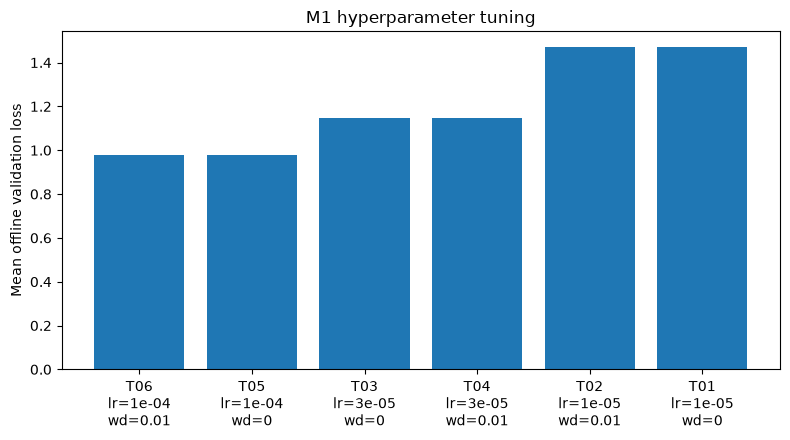

In [16]:
fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

plot_labels = [
    (
        f"{row.tuning_id}\n"
        f"lr={row.learning_rate:.0e}\n"
        f"wd={row.weight_decay:g}"
    )
    for row in tuning_results_df.itertuples()
]

ax.bar(
    np.arange(len(tuning_results_df)),
    tuning_results_df["validation_loss"],
)

ax.set_xticks(
    np.arange(len(tuning_results_df))
)

ax.set_xticklabels(
    plot_labels
)

ax.set_ylabel(
    "Mean offline validation loss"
)

ax.set_title(
    "M1 hyperparameter tuning"
)

fig.tight_layout()

tuning_figure_path = (
    FIGURES_DIR
    / "m1_hyperparameter_tuning_validation_loss.png"
)

fig.savefig(
    tuning_figure_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## 13. Select and freeze the best optimizer setting

In [17]:
best_tuning_row = (
    tuning_results_df.iloc[0]
)

BEST_LEARNING_RATE = float(
    best_tuning_row["learning_rate"]
)

BEST_WEIGHT_DECAY = float(
    best_tuning_row["weight_decay"]
)

best_config_summary = {
    "selected_tuning_id": str(
        best_tuning_row["tuning_id"]
    ),
    "learning_rate": BEST_LEARNING_RATE,
    "weight_decay": BEST_WEIGHT_DECAY,
    "validation_loss": float(
        best_tuning_row["validation_loss"]
    ),
    "tuning_seed": TUNING_SEED,
    "selection_rule": (
        "Minimum mean loss on frozen validation subset"
    ),
}

display(
    pd.DataFrame(
        [best_config_summary]
    ).T.rename(columns={0: "Value"})
)

best_optimizer_path = (
    EXPERIMENT_CONFIG_DIR
    / "selected_optimizer_v1.json"
)

with open(
    best_optimizer_path,
    "w",
) as f:
    json.dump(
        best_config_summary,
        f,
        indent=2,
    )

print("OPTIMIZER CONFIGURATION: FROZEN")

,Value
selected_tuning_id,T06
learning_rate,0.0001
weight_decay,0.01
validation_loss,0.976153
tuning_seed,42
selection_rule,Minimum mean loss on frozen validation subset


OPTIMIZER CONFIGURATION: FROZEN


## 14. Freeze the final training plan

The optimizer setting selected above is now fixed for **every final model**.

No model receives model-specific learning-rate tuning.

The final comparison uses:

- M1: seeds 42, 123, 2026
- M2-L: seed 42
- M2-E: seed 42
- M2-LE: seeds 42, 123, 2026

This produces the main three-seed M1 vs M2-LE comparison plus two single-seed ablations.

In [18]:
final_run_rows = []

for seed in PRIMARY_SEEDS:
    final_run_rows.append({
        "run_id": f"M1_seed{seed}",
        "variant": "M1",
        "seed": seed,
        "role": (
            "Primary baseline"
        ),
    })

final_run_rows.append({
    "run_id": "M2L_seed42",
    "variant": "M2-L",
    "seed": 42,
    "role": "Language ablation",
})

final_run_rows.append({
    "run_id": "M2E_seed42",
    "variant": "M2-E",
    "seed": 42,
    "role": "Environment ablation",
})

for seed in PRIMARY_SEEDS:
    final_run_rows.append({
        "run_id": f"M2LE_seed{seed}",
        "variant": "M2-LE",
        "seed": seed,
        "role": (
            "Primary proposed model"
        ),
    })

final_training_plan_df = pd.DataFrame(
    final_run_rows
)

final_training_plan_df[
    "learning_rate"
] = BEST_LEARNING_RATE

final_training_plan_df[
    "weight_decay"
] = BEST_WEIGHT_DECAY

final_training_plan_df[
    "steps"
] = FINAL_STEPS

final_training_plan_df[
    "batch_size"
] = FINAL_BATCH_SIZE

assert len(final_training_plan_df) == 8

display(final_training_plan_df)

final_training_plan_path = (
    EXPERIMENT_CONFIG_DIR
    / "final_training_plan_v1.csv"
)

final_training_plan_df.to_csv(
    final_training_plan_path,
    index=False,
)

final_training_manifest = {
    "plan_id": "v1",
    "selected_optimizer": best_config_summary,
    "final_steps": FINAL_STEPS,
    "batch_size": FINAL_BATCH_SIZE,
    "grad_clip_norm": GRAD_CLIP_NORM,
    "warmup_fraction": WARMUP_FRACTION,
    "min_lr_ratio": MIN_LR_RATIO,
    "primary_seeds": PRIMARY_SEEDS,
    "primary_comparison": [
        "M1",
        "M2-LE",
    ],
    "single_seed_ablations": [
        "M2-L",
        "M2-E",
    ],
    "validation_metric_role": (
        "Model selection / sanity only; "
        "closed-loop task success is primary."
    ),
}

with open(
    EXPERIMENT_CONFIG_DIR
    / "final_training_plan_v1.json",
    "w",
) as f:
    json.dump(
        final_training_manifest,
        f,
        indent=2,
    )

print("FINAL TRAINING PLAN: FROZEN")

,run_id,variant,seed,role,learning_rate,weight_decay,steps,batch_size
0,M1_seed42,M1,42,Primary baseline,0.0001,0.01,1500,4
1,M1_seed123,M1,123,Primary baseline,0.0001,0.01,1500,4
2,M1_seed2026,M1,2026,Primary baseline,0.0001,0.01,1500,4
3,M2L_seed42,M2-L,42,Language ablation,0.0001,0.01,1500,4
4,M2E_seed42,M2-E,42,Environment ablation,0.0001,0.01,1500,4
5,M2LE_seed42,M2-LE,42,Primary proposed model,0.0001,0.01,1500,4
6,M2LE_seed123,M2-LE,123,Primary proposed model,0.0001,0.01,1500,4
7,M2LE_seed2026,M2-LE,2026,Primary proposed model,0.0001,0.01,1500,4


FINAL TRAINING PLAN: FROZEN


## 15. Execute or reuse final training

Unlike tuning runs, final model checkpoints are preserved under:

`experiments/training/final/<run_id>/model/`

These directories should remain **gitignored** because model weights are large.

Every run persists:

- run manifest,
- training metrics,
- optional language assignment,
- final checkpoint + processors,
- checkpoint-reload validation result.

In [19]:
final_results = []

for _, row in final_training_plan_df.iterrows():

    result = train_and_validate_run(
        run_id=str(row["run_id"]),
        variant=str(row["variant"]),
        seed=int(row["seed"]),
        learning_rate=float(
            row["learning_rate"]
        ),
        weight_decay=float(
            row["weight_decay"]
        ),
        steps=int(row["steps"]),
        batch_size=int(
            row["batch_size"]
        ),
        root_dir=FINAL_OUTPUT_DIR,
        keep_model=True,
    )

    result["role"] = str(
        row["role"]
    )

    final_results.append(
        result
    )

final_results_df = pd.DataFrame(
    final_results
)

final_results_path = (
    METRICS_DIR
    / "final_training_results.csv"
)

final_results_df.to_csv(
    final_results_path,
    index=False,
)

display(
    final_results_df[
        [
            "run_id",
            "variant",
            "seed",
            "role",
            "validation_loss",
            "final_logged_train_loss",
            "training_seconds",
            "peak_logged_gpu_memory_gb",
        ]
    ]
)

assert len(final_results_df) == 8
assert (
    final_results_df["status"] == "PASS"
).all()

assert np.isfinite(
    final_results_df["validation_loss"]
).all()

print("ALL FINAL TRAINING RUNS: PASS")

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1213.28it/s]

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...



Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1890.91it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
M1_seed42 | step    1/1500 | loss=3.7748 | grad=26.927 | lr=1.33e-06
M1_seed42 | step   25/1500 | loss=1.9700 | grad=17.189 | lr=1.73e-05
M1_seed42 | step   50/1500 | loss=1.6426 | grad=7.694 | lr=3.40e-05
M1_seed42 | step   75/1500 | loss=1.1604 | grad=6.627 | lr=5.07e-05
M1_seed42 | step  100/1500 | loss=1.2074 | grad=6.563 | lr=6.73e-05
M1_seed42 | step  125/1500 | loss=1.1394 | grad=7.479 | lr=8.40e-05
M1_seed42 | step  150/1500 | loss=0.9872 | grad=6.082 | lr=1.00e-04
M1_seed42 | step  175/1500 | loss=1.3191 | grad=7.487 | lr=9.99e-05
M1_seed42 | step  200/1500 | loss=1.0106 | grad=5.097 | lr=9.97e-05
M1_seed42 | step  225/1500 | loss=1.0851 | grad=8.018 | lr=9.93e-05
M1_seed42 | step  250/1500 | loss=1.3040 | grad=6.340 | lr=9.87e-05
M1_seed42 | step  275/1500 | loss=0.8769 | grad=4.529 | lr=9.80e-05
M1_seed42 | step  300/1500 | loss=0.9934 | grad=6.844 | lr=9.71e-05
M1_seed42 | step  325/1500 | loss

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1975.87it/s]


...

Reducing the number of VLM layers to 16 ...
Loading weights from local directory
M2LE_seed2026 | step    1/1500 | loss=4.0882 | grad=28.058 | lr=1.33e-06
M2LE_seed2026 | step   25/1500 | loss=9.0527 | grad=72.331 | lr=1.73e-05
M2LE_seed2026 | step   50/1500 | loss=1.2874 | grad=8.314 | lr=3.40e-05
M2LE_seed2026 | step   75/1500 | loss=1.1878 | grad=7.493 | lr=5.07e-05
M2LE_seed2026 | step  100/1500 | loss=1.3371 | grad=10.248 | lr=6.73e-05
M2LE_seed2026 | step  125/1500 | loss=1.5280 | grad=11.034 | lr=8.40e-05
M2LE_seed2026 | step  150/1500 | loss=0.9373 | grad=6.361 | lr=1.00e-04
M2LE_seed2026 | step  175/1500 | loss=1.0904 | grad=7.157 | lr=9.99e-05
M2LE_seed2026 | step  200/1500 | loss=1.0396 | grad=9.786 | lr=9.97e-05
M2LE_seed2026 | step  225/1500 | loss=1.0490 | grad=5.771 | lr=9.93e-05
M2LE_seed2026 | step  250/1500 | loss=1.2655 | grad=6.622 | lr=9.87e-05
M2LE_seed2026 | step  275/1500 | loss=0.8708 | grad=6.799 | lr=9.80e-05
M2LE_seed2026 | step  300/1500 | loss=1.0495 | grad

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1947.80it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
M2LE_seed2026: PASS | validation_loss=0.64492


,run_id,variant,seed,role,validation_loss,final_logged_train_loss,training_seconds,peak_logged_gpu_memory_gb
0,M1_seed42,M1,42,Primary baseline,0.647234,0.442872,212.216270,2.104808
1,M1_seed123,M1,123,Primary baseline,0.663268,0.602583,212.858200,2.104808
2,M1_seed2026,M1,2026,Primary baseline,0.662571,0.618505,213.149722,2.104808
3,M2L_seed42,M2-L,42,Language ablation,0.657187,0.441194,215.563376,2.104808
4,M2E_seed42,M2-E,42,Environment ablation,0.642406,0.438668,223.462137,2.104808
5,M2LE_seed42,M2-LE,42,Primary proposed model,0.653671,0.433815,230.262045,2.104808
6,M2LE_seed123,M2-LE,123,Primary proposed model,0.700583,0.511856,227.081159,2.104808
7,M2LE_seed2026,M2-LE,2026,Primary proposed model,0.644916,0.489404,227.013961,2.104808


ALL FINAL TRAINING RUNS: PASS


## 16. Final training diagnostics

,variant,n_runs,mean_validation_loss,std_validation_loss,mean_training_seconds,mean_peak_gpu_memory_gb
0,M1,3,0.657691,0.009063,212.741397,2.104808
1,M2-E,1,0.642406,NaN,223.462137,2.104808
2,M2-L,1,0.657187,NaN,215.563376,2.104808
3,M2-LE,3,0.666390,0.029934,228.119055,2.104808


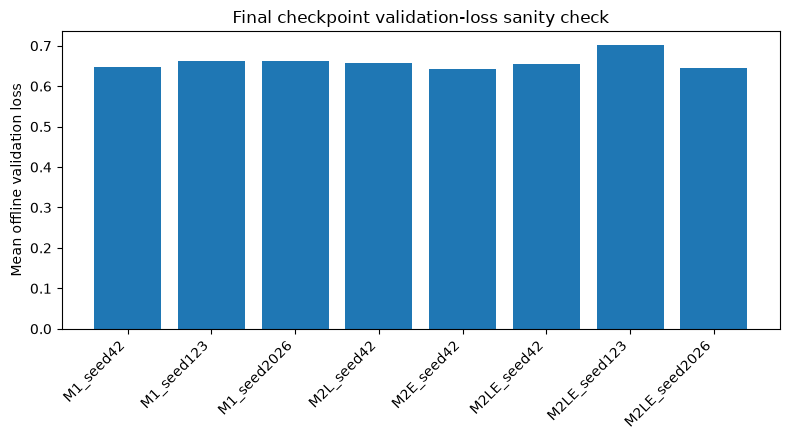

In [20]:
variant_summary_df = (
    final_results_df
    .groupby("variant")
    .agg(
        n_runs=("run_id", "count"),
        mean_validation_loss=(
            "validation_loss",
            "mean",
        ),
        std_validation_loss=(
            "validation_loss",
            "std",
        ),
        mean_training_seconds=(
            "training_seconds",
            "mean",
        ),
        mean_peak_gpu_memory_gb=(
            "peak_logged_gpu_memory_gb",
            "mean",
        ),
    )
    .reset_index()
)

display(variant_summary_df)

fig, ax = plt.subplots(
    figsize=(8, 4.5)
)

x = np.arange(
    len(final_results_df)
)

ax.bar(
    x,
    final_results_df[
        "validation_loss"
    ],
)

ax.set_xticks(x)

ax.set_xticklabels(
    final_results_df["run_id"],
    rotation=45,
    ha="right",
)

ax.set_ylabel(
    "Mean offline validation loss"
)

ax.set_title(
    "Final checkpoint validation-loss sanity check"
)

fig.tight_layout()

final_validation_figure_path = (
    FIGURES_DIR
    / "final_checkpoint_validation_loss.png"
)

fig.savefig(
    final_validation_figure_path,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

### Interpretation boundary

A lower validation loss here does **not** prove that a model is more robust in the simulator.

For example:

- M2-E may have similar L0 validation loss to M1 but behave better under lighting changes.
- M2-L may have similar L0 validation loss but understand paraphrased instructions better.
- M2-LE may trade a small amount of ID loss for a much smaller OOD generalization gap.

Those claims require the controlled closed-loop experiments in Notebook 04.

## 17. Verify final model artifacts

In [21]:
artifact_rows = []

for _, row in final_training_plan_df.iterrows():

    run_dir = (
        FINAL_OUTPUT_DIR
        / str(row["run_id"])
    )

    model_dir = (
        run_dir
        / "model"
    )

    artifact_rows.append({
        "run_id": str(row["run_id"]),
        "variant": str(row["variant"]),
        "seed": int(row["seed"]),
        "config_json": (
            model_dir / "config.json"
        ).exists(),
        "processor_saved": any(
            model_dir.glob(
                "*processor*.json"
            )
        ),
        "train_metrics": (
            run_dir
            / "train_metrics.csv"
        ).exists(),
        "result_json": (
            run_dir
            / "result.json"
        ).exists(),
        "run_manifest": (
            run_dir
            / "run_manifest.json"
        ).exists(),
        "language_assignment": (
            (
                run_dir
                / "language_assignment.csv"
            ).exists()
            if str(row["variant"])
            in {"M2-L", "M2-LE"}
            else True
        ),
    })

artifact_audit_df = pd.DataFrame(
    artifact_rows
)

artifact_audit_df[
    "artifact_pass"
] = artifact_audit_df[
    [
        "config_json",
        "processor_saved",
        "train_metrics",
        "result_json",
        "run_manifest",
        "language_assignment",
    ]
].all(axis=1)

display(artifact_audit_df)

FINAL_ARTIFACTS_PASS = bool(
    artifact_audit_df[
        "artifact_pass"
    ].all()
)

assert FINAL_ARTIFACTS_PASS

artifact_audit_df.to_csv(
    METRICS_DIR
    / "final_artifact_audit.csv",
    index=False,
)

print("FINAL MODEL ARTIFACT AUDIT: PASS")

,run_id,variant,seed,config_json,processor_saved,train_metrics,result_json,run_manifest,language_assignment,artifact_pass
0,M1_seed42,M1,42,True,True,True,True,True,True,True
1,M1_seed123,M1,123,True,True,True,True,True,True,True
2,M1_seed2026,M1,2026,True,True,True,True,True,True,True
3,M2L_seed42,M2-L,42,True,True,True,True,True,True,True
4,M2E_seed42,M2-E,42,True,True,True,True,True,True,True
5,M2LE_seed42,M2-LE,42,True,True,True,True,True,True,True
6,M2LE_seed123,M2-LE,123,True,True,True,True,True,True,True
7,M2LE_seed2026,M2-LE,2026,True,True,True,True,True,True,True


FINAL MODEL ARTIFACT AUDIT: PASS


## 18. Save Notebook 04 evaluation hand-off manifest

In [22]:
evaluation_handoff = {
    "source_notebook": (
        "03_tuning_and_final_training"
    ),
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "split_sha256": notebook02_summary[
        "split_sha256"
    ],
    "selected_learning_rate": (
        BEST_LEARNING_RATE
    ),
    "selected_weight_decay": (
        BEST_WEIGHT_DECAY
    ),
    "final_steps": FINAL_STEPS,
    "models": {},
    "evaluation_plan": {
        "E0": "standard ID LIBERO-Spatial",
        "E1": "language L0-L3",
        "E2": "seen environmental shifts",
        "E3": "held-out perturbation categories",
        "E4": "combined perturbations where feasible",
    },
    "primary_metric": "task success rate",
    "secondary_metrics": [
        "generalization gap",
        "completion steps",
        "inference latency",
        "failure taxonomy",
    ],
}

for _, result in final_results_df.iterrows():

    run_id = str(
        result["run_id"]
    )

    evaluation_handoff[
        "models"
    ][run_id] = {
        "variant": str(
            result["variant"]
        ),
        "seed": int(
            result["seed"]
        ),
        "checkpoint": str(
            (
                FINAL_OUTPUT_DIR
                / run_id
                / "model"
            ).relative_to(
                REPO_ROOT
            )
        ),
        "validation_loss": float(
            result[
                "validation_loss"
            ]
        ),
    }

evaluation_handoff_path = (
    EXPERIMENT_CONFIG_DIR
    / "notebook04_evaluation_handoff_v1.json"
)

with open(
    evaluation_handoff_path,
    "w",
) as f:
    json.dump(
        evaluation_handoff,
        f,
        indent=2,
    )

print(
    "Evaluation hand-off saved:",
    evaluation_handoff_path,
)

Evaluation hand-off saved: /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/notebook04_evaluation_handoff_v1.json


## 19. Final Notebook 03 status

In [26]:
# ================================================================
# 19. Final Notebook 03 status
# ================================================================

final_checks = {

    "Notebook 02 prerequisite":
        notebook02_summary["status"] == "PASS",

    "Frozen split integrity":
        (
            len(train_ids) == 346
            and len(validation_ids) == 86
            and set(train_ids).isdisjoint(validation_ids)
        ),

    "Frozen validation subset":
        (
            len(validation_subset_df)
            == 10 * VAL_FRAMES_PER_TASK
            and validation_subset_df[
                "task_index"
            ].nunique() == 10
        ),

    "Language L0/L1/L2 assignment":
        (
            set(
                seed42_language_audit[
                    "language_level"
                ]
            )
            == {"L0", "L1", "L2"}
        ),

    "L3 excluded from training":
        (
            "L3"
            not in set(
                seed42_language_audit[
                    "language_level"
                ]
            )
        ),

    "Custom loop preflight":
        PREFLIGHT_PASS,

    "Six tuning runs complete":
        (
            len(tuning_results_df) == 6
            and np.isfinite(
                tuning_results_df[
                    "validation_loss"
                ]
            ).all()
        ),

    "Optimizer selection frozen":
        best_optimizer_path.exists(),

    "Eight final runs complete":
        (
            len(final_results_df) == 8
            and (
                final_results_df[
                    "status"
                ]
                == "PASS"
            ).all()
        ),

    "Three M1 seeds":
        (
            len(
                final_results_df[
                    final_results_df[
                        "variant"
                    ]
                    == "M1"
                ]
            )
            == 3
        ),

    "Three M2-LE seeds":
        (
            len(
                final_results_df[
                    final_results_df[
                        "variant"
                    ]
                    == "M2-LE"
                ]
            )
            == 3
        ),

    "M2-L ablation":
        (
            "M2-L"
            in set(
                final_results_df[
                    "variant"
                ]
            )
        ),

    "M2-E ablation":
        (
            "M2-E"
            in set(
                final_results_df[
                    "variant"
                ]
            )
        ),

    "Final artifact audit":
        FINAL_ARTIFACTS_PASS,

    "Notebook 04 handoff":
        evaluation_handoff_path.exists(),
}


# ================================================================
# Normalize NumPy / Pandas boolean values for JSON serialization
# ================================================================

final_checks = {
    check: bool(passed)
    for check, passed in final_checks.items()
}


# ================================================================
# Display final checks
# ================================================================

status_df = pd.DataFrame(
    [
        {
            "check": check,
            "status": (
                "PASS"
                if passed
                else "FAIL"
            ),
        }
        for check, passed in final_checks.items()
    ]
)

display(status_df)


# ================================================================
# Determine overall Notebook 03 status
# ================================================================

NOTEBOOK_03_PASS = bool(
    all(
        final_checks.values()
    )
)


# ================================================================
# Build reproducibility summary
# ================================================================

notebook03_summary = {

    "notebook":
        "03_tuning_and_final_training",

    "status":
        (
            "PASS"
            if NOTEBOOK_03_PASS
            else "FAIL"
        ),

    "project_git_sha":
        PROJECT_GIT_SHA,

    "dataset_repo_id":
        DATASET_REPO_ID,

    "dataset_revision":
        DATASET_REVISION,

    "base_model_repo_id":
        BASE_MODEL_REPO_ID,

    "base_model_revision":
        BASE_MODEL_REVISION,

    "split_file":
        notebook02_summary[
            "split_file"
        ],

    "split_sha256":
        notebook02_summary[
            "split_sha256"
        ],

    "validation_subset":
        str(
            validation_subset_path
            .relative_to(
                REPO_ROOT
            )
        ),

    "tuning_search_space":
        str(
            tuning_search_space_path
            .relative_to(
                REPO_ROOT
            )
        ),

    "selected_optimizer": {
        "selected_tuning_id":
            str(
                best_config_summary[
                    "selected_tuning_id"
                ]
            ),

        "learning_rate":
            float(
                best_config_summary[
                    "learning_rate"
                ]
            ),

        "weight_decay":
            float(
                best_config_summary[
                    "weight_decay"
                ]
            ),

        "validation_loss":
            float(
                best_config_summary[
                    "validation_loss"
                ]
            ),

        "tuning_seed":
            int(
                best_config_summary[
                    "tuning_seed"
                ]
            ),

        "selection_rule":
            str(
                best_config_summary[
                    "selection_rule"
                ]
            ),
    },

    "final_training_plan":
        str(
            final_training_plan_path
            .relative_to(
                REPO_ROOT
            )
        ),

    "final_training_results":
        str(
            final_results_path
            .relative_to(
                REPO_ROOT
            )
        ),

    "evaluation_handoff":
        str(
            evaluation_handoff_path
            .relative_to(
                REPO_ROOT
            )
        ),

    "checks":
        final_checks,
}


# ================================================================
# Save Notebook 03 summary
# ================================================================

notebook03_summary_path = (
    METRICS_DIR
    / "notebook03_summary.json"
)

with open(
    notebook03_summary_path,
    "w",
) as f:

    json.dump(
        notebook03_summary,
        f,
        indent=2,
    )


# ================================================================
# Final marker-friendly status output
# ================================================================

print("=" * 68)

print(
    "NOTEBOOK 03 — FINAL STATUS"
)

print("=" * 68)


for check, passed in final_checks.items():

    print(
        f"{check:<50} "
        f"{'PASS' if passed else 'FAIL'}"
    )


print("-" * 68)

print(
    f"{'NOTEBOOK 03 STATUS':<50} "
    f"{'PASS' if NOTEBOOK_03_PASS else 'FAIL'}"
)

print("-" * 68)


# ================================================================
# Final assertion
# ================================================================

assert NOTEBOOK_03_PASS


# ================================================================
# Notebook 04 handoff
# ================================================================

print()

print(
    "Ready for Notebook 04:"
)

print(
    "Closed-loop ID/OOD evaluation "
    "and critical analysis."
)

print()

print(
    "Summary saved:",
    notebook03_summary_path,
)

,check,status
0,Notebook 02 prerequisite,PASS
1,Frozen split integrity,PASS
2,Frozen validation subset,PASS
3,Language L0/L1/L2 assignment,PASS
4,L3 excluded from training,PASS
5,Custom loop preflight,PASS
6,Six tuning runs complete,PASS
7,Optimizer selection frozen,PASS
8,Eight final runs complete,PASS
9,Three M1 seeds,PASS


NOTEBOOK 03 — FINAL STATUS
Notebook 02 prerequisite                           PASS
Frozen split integrity                             PASS
Frozen validation subset                           PASS
Language L0/L1/L2 assignment                       PASS
L3 excluded from training                          PASS
Custom loop preflight                              PASS
Six tuning runs complete                           PASS
Optimizer selection frozen                         PASS
Eight final runs complete                          PASS
Three M1 seeds                                     PASS
Three M2-LE seeds                                  PASS
M2-L ablation                                      PASS
M2-E ablation                                      PASS
Final artifact audit                               PASS
Notebook 04 handoff                                PASS
--------------------------------------------------------------------
NOTEBOOK 03 STATUS                                 PASS
--------

## Notebook 03 interpretation

Notebook 03 completes the **training and model-selection phase**.

What has now been frozen:

1. the train/validation split,
2. the validation frame subset,
3. the optimizer search space,
4. the selected learning rate and weight decay,
5. the final training budget,
6. the language perturbation policy,
7. the environmental augmentation policy,
8. the final seed allocation,
9. all final checkpoints.

The remaining question is no longer **“can the models be trained?”**

Notebook 04 addresses the actual research question:

> **Does robustness-oriented fine-tuning improve closed-loop generalization under linguistic and environmental distribution shifts, and what trade-offs or failure modes emerge?**